In [1]:
# 1. Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

In [2]:
# 2. Load the customer credit card dataset
data = pd.read_csv(r"D:\Downloads\DL DATASET\Credit Card Customer Data - Credit Card Customer Data.csv")

In [3]:
print("Dataset:")
print(data.head())


Dataset:
   Sl_No  Customer Key  Avg_Credit_Limit  Total_Credit_Cards  \
0      1         87073            100000                   2   
1      2         38414             50000                   3   
2      3         17341             50000                   7   
3      4         40496             30000                   5   
4      5         47437            100000                   6   

   Total_visits_bank  Total_visits_online  Total_calls_made  
0                  1                    1                 0  
1                  0                   10                 9  
2                  1                    3                 4  
3                  1                    1                 4  
4                  0                   12                 3  


In [4]:
# Select useful customer features (exclude ID columns)
features = [
    'Avg_Credit_Limit',
    'Total_Credit_Cards',
    'Total_visits_bank',
    'Total_visits_online',
    'Total_calls_made'
]

X = data[features].copy()

# Handle missing values
X = X.fillna(X.median())


In [5]:
# Convert data into a standard scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [6]:
# 3. Split the dataset
X_train, X_test = train_test_split(
    X_scaled, test_size=0.2, random_state=42
)


In [12]:
# 4. Build the Encoder
input_dim = X_train.shape[1]

input_layer = Input(shape=(input_dim,))

encoded = Dense(4, activation='relu')(input_layer)
encoded = Dense(2, activation='relu')(encoded)

# 5. Build the Decoder
decoded = Dense(4, activation='relu')(encoded)
decoded = Dense(input_dim, activation='linear')(decoded)

# Create Autoencoder
autoencoder = Model(input_layer, decoded)

#We use linear activation because our customer data contains numerical values that are not limited to 0 and 1, while Sigmoid restricts output values between 0 and 1.

In [13]:

# 6. Compile the model
autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

autoencoder.summary()
#We use MSE because the dataset contains numerical values, while Binary Crossentropy is mainly used for binary values (0 or 1).

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)           │ (None, 5)                   │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 4)                   │              24 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 2)                   │              10 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 4)                   │              12 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 5)                   │              25 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 71 (284.00 B)

 Trainable params: 71 (284.00 B)

 Non-trainable params: 0 (0.00 B)

In [14]:
# 7. Train the Autoencoder
history = autoencoder.fit(
    X_train, X_train,
    epochs=50,
    batch_size=16,
    validation_data=(X_test, X_test),
    shuffle=True
)

Epoch 1/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.9944 - mae: 0.7616 - val_loss: 0.9553 - val_mae: 0.7409
Epoch 2/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.9337 - mae: 0.7365 - val_loss: 0.9105 - val_mae: 0.7231
Epoch 3/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.8957 - mae: 0.7212 - val_loss: 0.8728 - val_mae: 0.7065
Epoch 4/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.8593 - mae: 0.7063 - val_loss: 0.8299 - val_mae: 0.6900
Epoch 5/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.8179 - mae: 0.6903 - val_loss: 0.7779 - val_mae: 0.6714
Epoch 6/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.7706 - mae: 0.6727 - val_loss: 0.7220 - val_mae: 0.6521
Epoch 7/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.7212 - mae: 0.6547 - val_loss: 0.6684 - val_mae: 0.6323
Epoch 8/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.6722 - mae: 0.6363 - val_loss: 0.6189 - val_mae: 0.6131
Epoch 9/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6284 - mae: 

In [21]:
# 8. Calculate reconstruction error
#Calculate mean sqaure error(so np.mean (np.square)) is used.Remember in this way.
train_prediction = autoencoder.predict(X_train)
train_error = np.mean(
    np.square(X_train - train_prediction), axis=1
)

test_prediction = autoencoder.predict(X_scaled)
reconstruction_error = np.mean(
    np.square(X_scaled - test_prediction), axis=1
)


17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


In [16]:
# 9. Set threshold for anomaly detection
threshold = np.percentile(train_error, 95)

print("Anomaly Threshold:", threshold)

Anomaly Threshold: 0.4846118912509608


In [17]:
# 10. Detect anomalies
data['Reconstruction_Error'] = reconstruction_error

data['Anomaly'] = np.where(
    reconstruction_error > threshold,
    'Anomaly',
    'Normal'
)


In [19]:
# Display results
print("\nAnomaly Detection Results:")

print(data[['Reconstruction_Error', 'Anomaly']].head(10))

# Count normal and anomalous customers
print("\nCustomer Classification:")
print(data['Anomaly'].value_counts())


Anomaly Detection Results:
   Reconstruction_Error  Anomaly
0              1.295482  Anomaly
1              1.058897  Anomaly
2              0.295927   Normal
3              0.204867   Normal
4              0.354276   Normal
5              0.276381   Normal
6              0.351271   Normal
7              0.689506  Anomaly
8              0.572131  Anomaly
9              0.320698   Normal

Customer Classification:
Anomaly
Normal     625
Anomaly     35
Name: count, dtype: int64


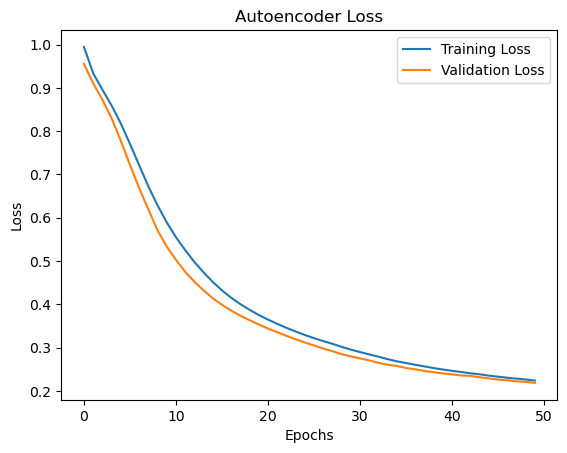

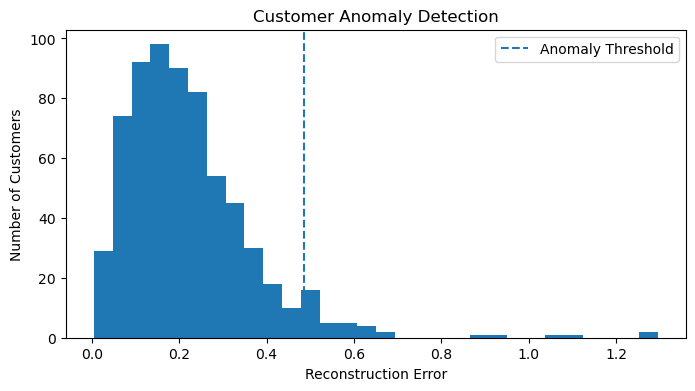

In [20]:
# 11. Plot training and validation loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Autoencoder Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

# 12. Visualize anomalies
plt.figure(figsize=(8, 4))
plt.hist(reconstruction_error, bins=30)
plt.axvline(threshold, linestyle='--', label='Anomaly Threshold')
plt.title('Customer Anomaly Detection')
plt.xlabel('Reconstruction Error')
plt.ylabel('Number of Customers')
plt.legend()
plt.show()